### The machine learning model was developed to predict patient outcomes using clinical and laboratory measurements. In a real-world healthcare environment, the model can serve as an early warning system by identifying high-risk cirrhosis patients who may require closer monitoring, advanced treatment, or transplant evaluation. By supporting clinicians with data-driven insights, the model has the potential to improve patient management and optimize healthcare resources.

C = Censored (alive at last follow-up)
D = Death
CL = Liver transplant

# importing  Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import  accuracy_score,classification_report,confusion_matrix



import the Dataset

In [2]:
cirr = pd.read_csv('C://Users/DELL/Documents/mltest/ml - Copy/cirrhosis.csv')

In [3]:
cirr.head()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


Data informations

In [4]:
cirr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    object 
 3   Drug           312 non-null    object 
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    object 
 6   Ascites        312 non-null    object 
 7   Hepatomegaly   312 non-null    object 
 8   Spiders        312 non-null    object 
 9   Edema          418 non-null    object 
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombi

In [5]:
cirr.describe()

,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.000000,418.000000,418.000000,418.000000,284.000000,418.000000,310.000000,312.000000,312.000000,282.000000,407.000000,416.000000,412.000000
mean,209.500000,1917.782297,18533.351675,3.220813,369.510563,3.497440,97.648387,1982.655769,122.556346,124.702128,257.024570,10.731731,3.024272
std,120.810458,1104.672992,3815.845055,4.407506,231.944545,0.424972,85.613920,2140.388824,56.699525,65.148639,98.325585,1.022000,0.882042
min,1.000000,41.000000,9598.000000,0.300000,120.000000,1.960000,4.000000,289.000000,26.350000,33.000000,62.000000,9.000000,1.000000
25%,105.250000,1092.750000,15644.500000,0.800000,249.500000,3.242500,41.250000,871.500000,80.600000,84.250000,188.500000,10.000000,2.000000
50%,209.500000,1730.000000,18628.000000,1.400000,309.500000,3.530000,73.000000,1259.000000,114.700000,108.000000,251.000000,10.600000,3.000000
75%,313.750000,2613.500000,21272.500000,3.400000,400.000000,3.770000,123.000000,1980.000000,151.900000,151.000000,318.000000,11.100000,4.000000
max,418.000000,4795.000000,28650.000000,28.000000,1775.000000,4.640000,588.000000,13862.400000,457.250000,598.000000,721.000000,18.000000,4.000000


In [6]:
cirr.isnull().sum()

ID                 0
N_Days             0
Status             0
Drug             106
Age                0
Sex                0
Ascites          106
Hepatomegaly     106
Spiders          106
Edema              0
Bilirubin          0
Cholesterol      134
Albumin            0
Copper           108
Alk_Phos         106
SGOT             106
Tryglicerides    136
Platelets         11
Prothrombin        2
Stage              6
dtype: int64

Check Target Variable

In [7]:
cirr['Status'].value_counts()

Status
C     232
D     161
CL     25
Name: count, dtype: int64

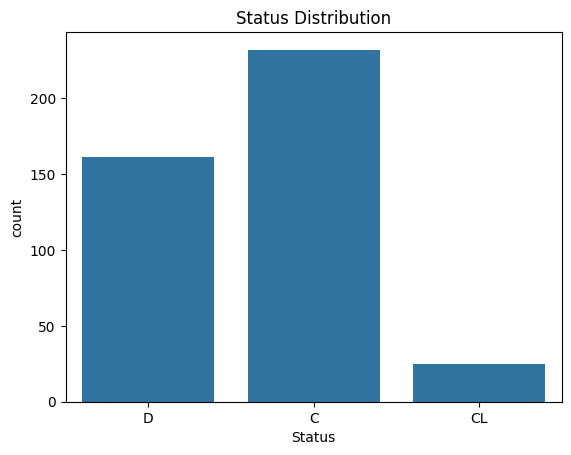

In [8]:
sns.countplot(x='Status', data=cirr)
plt.title('Status Distribution')
plt.show()

Missing Value Treatment and Separate numerical and categorical columns.

In [9]:
num_cols = cirr.select_dtypes(include=['int64','float64']).columns

cat_cols = cirr.select_dtypes(include=['object']).columns

In [10]:
cirr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    object 
 3   Drug           312 non-null    object 
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    object 
 6   Ascites        312 non-null    object 
 7   Hepatomegaly   312 non-null    object 
 8   Spiders        312 non-null    object 
 9   Edema          418 non-null    object 
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombi

In [11]:
for col in num_cols:
    cirr[col].fillna(cirr[col].median(), inplace=True)

In [12]:
cirr.head()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [13]:
for col in cat_cols:
    cirr[col].fillna(cirr[col].mode()[0], inplace=True)

In [14]:
cirr.isnull().sum().sum()

np.int64(0)

Exploratory Data Analysis

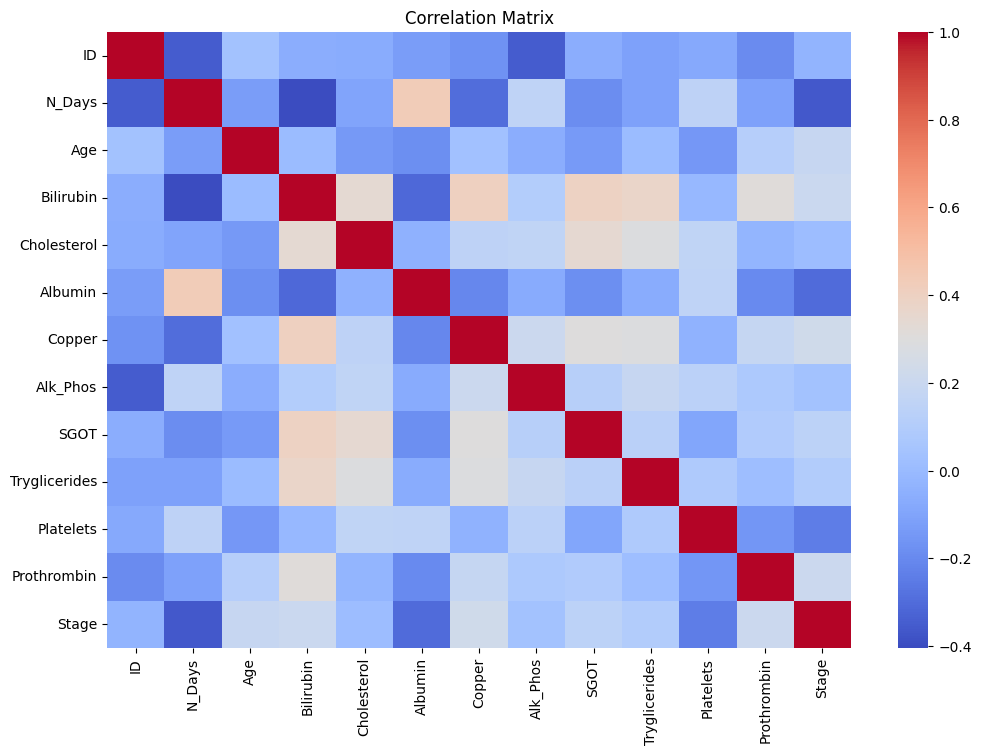

In [15]:
plt.figure(figsize=(12,8))

sns.heatmap(
    cirr[num_cols].corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Correlation Matrix')
plt.show()

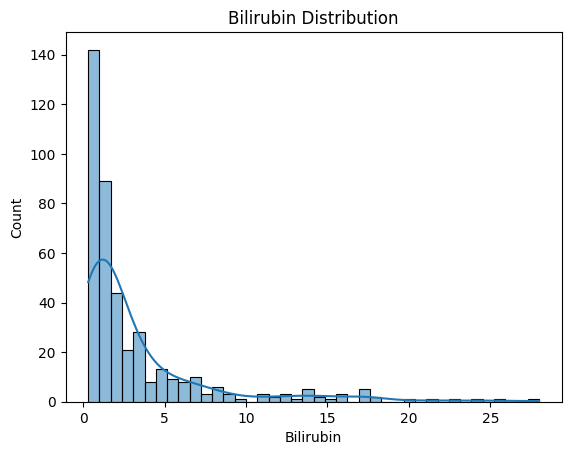

In [16]:
sns.histplot(cirr['Bilirubin'], kde=True)

plt.title('Bilirubin Distribution')
plt.show()

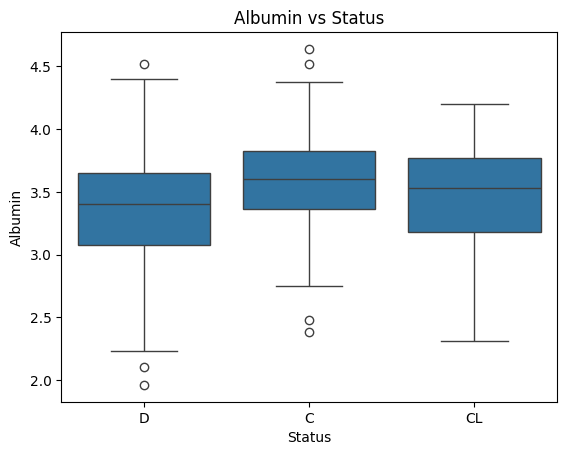

In [17]:
sns.boxplot(
    x='Status',
    y='Albumin',
    data=cirr 
)

plt.title('Albumin vs Status')
plt.show()

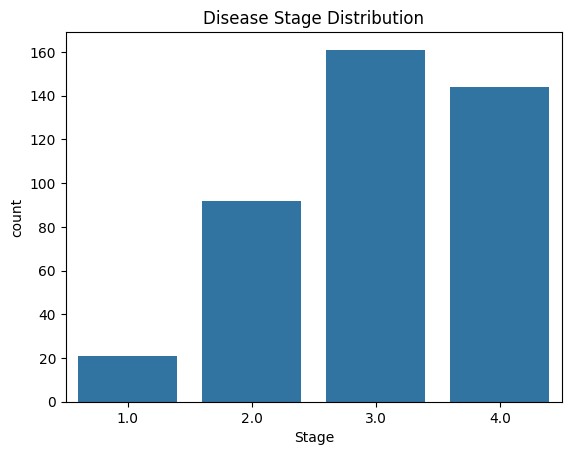

In [18]:
sns.countplot(x='Stage', data=cirr)

plt.title('Disease Stage Distribution')
plt.show()

Encode Categorical Variables

In [19]:
label_encoders = {}

for col in cat_cols:
    
    le = LabelEncoder()
    
    cirr[col] = le.fit_transform(cirr[col])
    
    label_encoders[col] = le

In [20]:
cirr.head()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,2,0,21464,0,1,1,1,2,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,0,0,20617,0,0,1,1,0,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,2,0,25594,1,0,0,0,1,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,2,0,19994,0,0,1,1,1,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,1,1,13918,0,0,1,1,0,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [21]:
# Clean 'Age' column (convert days to years)
cirr['Age'] = cirr['Age'] / 365.25

In [22]:
cirr.head()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,2,0,58.765229,0,1,1,1,2,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,0,0,56.446270,0,0,1,1,0,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,2,0,70.072553,1,0,0,0,1,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,2,0,54.740589,0,0,1,1,1,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,1,1,38.105407,0,0,1,1,0,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


Define Features and Target

In [23]:
X = cirr.drop(['Status', 'ID', 'N_Days'], axis=1)

y = cirr['Status']

train_test split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42,stratify=y)

Build Random Forest Model

rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=42
)

In [25]:
rf = RandomForestClassifier(  n_estimators=300,class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

prediction

In [26]:
y_pred = rf.predict(X_test)

Evaluate Model
Accuracy

In [27]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy*100,2), "%")

Accuracy: 72.62 %


In [28]:
te = label_encoders['Status']

In [29]:
ui = sorted(te.transform(te.classes_))
ol = te.inverse_transform(ui)

In [30]:
print(classification_report(y_test, y_pred, target_names=ol))

              precision    recall  f1-score   support

           C       0.75      0.87      0.80        47
          CL       0.00      0.00      0.00         5
           D       0.71      0.62      0.67        32

    accuracy                           0.73        84
   macro avg       0.49      0.50      0.49        84
weighted avg       0.69      0.73      0.70        84



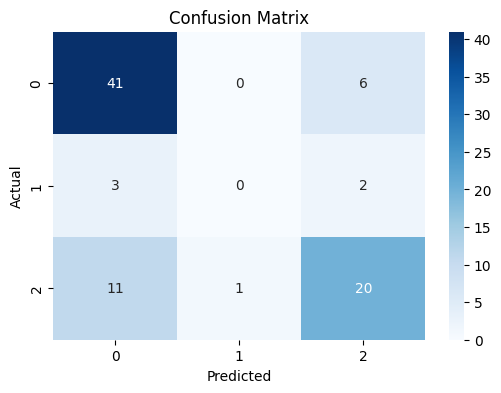

In [31]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Model Comparison

In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

In [33]:
dt = DecisionTreeClassifier(class_weight='balanced',random_state=42)

dt.fit(X_train, y_train)

pred_dt = dt.predict(X_test)

print(
    "Decision Tree Accuracy:",
    accuracy_score(y_test, pred_dt)
)

Decision Tree Accuracy: 0.5952380952380952


In [34]:
from sklearn.preprocessing import StandardScaler



In [35]:

# Scale data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model
lr = LogisticRegression(
    max_iter=5000,
    class_weight='balanced',
)

lr.fit(X_train_scaled, y_train)

# Predict
pred_lr = lr.predict(X_test_scaled)

print(
    "Logistic Regression Accuracy:",
    accuracy_score(y_test, pred_lr)
)


Logistic Regression Accuracy: 0.6428571428571429


Hyperparameter Tuning with GridSearchCV

In [36]:
from sklearn.model_selection import GridSearchCV

In [37]:
param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

Initialize Random Forest

In [38]:
rf = RandomForestClassifier(class_weight='balanced',random_state=42)

In [39]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)


best_rf = grid_search.best_estimator_

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


Best Parameters

In [40]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}


Best cross-validation

In [41]:
print("Best CV Score:",
      grid_search.best_score_)

Best CV Score: 0.757259158751696


Train Best Model

In [42]:
b_rf = grid_search.best_estimator_



In [43]:
y_pred_tuned = b_rf.predict(X_test)

Evaluating Tuned model accuracy

In [44]:
accuracy = accuracy_score(y_test,y_pred_tuned)
print(f"Tuned Accuracy: {accuracy:.4f}")

Tuned Accuracy: 0.7143


In [45]:
te = label_encoders['Status']

In [46]:
ui = sorted(te.transform(te.classes_))
ol = te.inverse_transform(ui)

In [47]:
print(classification_report(y_test,y_pred_tuned, target_names=ol))

              precision    recall  f1-score   support

           C       0.81      0.83      0.82        47
          CL       0.12      0.20      0.15         5
           D       0.71      0.62      0.67        32

    accuracy                           0.71        84
   macro avg       0.55      0.55      0.55        84
weighted avg       0.73      0.71      0.72        84



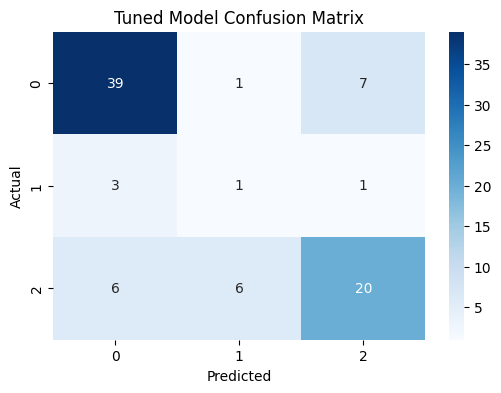

In [48]:
cm = confusion_matrix(
    y_test,
    y_pred_tuned
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title(
    'Tuned Model Confusion Matrix'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [49]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42
)

In [50]:
xgb.fit(X_train, y_train)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_metho

In [51]:
y_pred_xgb = xgb.predict(X_test)

In [52]:
ui = sorted(te.transform(te.classes_))
ol = te.inverse_transform(ui)

In [53]:
from sklearn.metrics import accuracy_score, classification_report

print("XGBoost Accuracy:",accuracy_score(y_test, y_pred_xgb))

print(classification_report(y_test, y_pred_xgb, target_names=ol))

XGBoost Accuracy: 0.75
              precision    recall  f1-score   support

           C       0.77      0.87      0.82        47
          CL       0.00      0.00      0.00         5
           D       0.81      0.69      0.75        32

    accuracy                           0.75        84
   macro avg       0.53      0.52      0.52        84
weighted avg       0.74      0.75      0.74        84



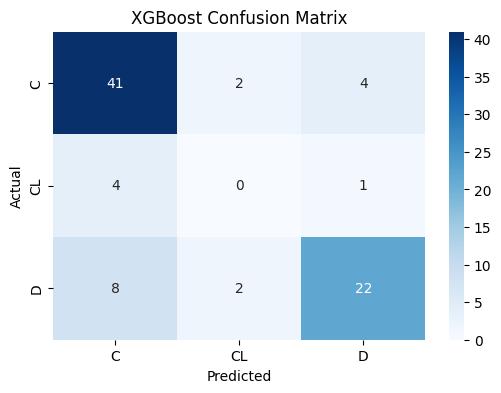

In [54]:


# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['C', 'CL', 'D'],
    yticklabels=['C', 'CL', 'D']
)

plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [55]:
print(type(best_rf))


<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [56]:
print(X_test.shape)

(84, 17)


In [57]:
print(y_test.shape)

(84,)


In [58]:
# Double-check what columns are actually in your datasets
print("Train features:", list(X_train.columns))
print("Test features:", list(X_test.columns))

Train features: ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']
Test features: ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


In [59]:
new_patient = pd.DataFrame({
    'Age': [55],
    'Sex': [1],
    'Drug': [0],
    'Ascites': [1],
    'Hepatomegaly': [1],
    'Spiders': [0],
    'Edema': [0],
    'Bilirubin': [5.2],
    'Cholesterol': [250],
    'Albumin': [2.8],
    'Copper': [180],
    'Alk_Phos': [1800],
    'SGOT': [120],
    'Tryglicerides': [150],
    'Platelets': [180],
    'Prothrombin': [12.5],
    'Stage': [4]
})

In [60]:
new_patient = new_patient.reindex(
    columns=best_rf.feature_names_in_,
    fill_value=0
)

In [61]:
prediction = best_rf.predict(new_patient)

print(prediction)

[2]


In [62]:
print(te.classes_)

['C' 'CL' 'D']


Multiple machine learning models were evaluated for predicting cirrhosis patient outcomes. After removing non-clinical and potentially leaking variables (ID and N_Days), XGBoost achieved an accuracy of 75%, outperforming the baseline Random Forest model. The results demonstrate that gradient boosting techniques can effectively capture complex relationships between clinical and laboratory variables while maintaining good generalization performance on unseen patient data

In [69]:
new_patient = pd.DataFrame({
    'Age': [30],
    'Sex': [1],
    'Drug': [0],
    'Ascites': [0],
    'Hepatomegaly': [0],
    'Spiders': [0],
    'Edema': [0],
    'Bilirubin': [1.2],
    'Cholesterol': [100],
    'Albumin': [0.8],
    'Copper': [120],
    'Alk_Phos': [1200],
    'SGOT': [120],
    'Tryglicerides': [150],
    'Platelets': [180],
    'Prothrombin': [12.5],
    'Stage': [2]
})

In [70]:
new_patient = new_patient.reindex(
    columns=best_rf.feature_names_in_,
    fill_value=0
)

In [71]:
prediction = best_rf.predict(new_patient)

print(prediction)

[0]
